# Rate and volatility drivers of option value

An interest-rate option responds to both its forward rate and volatility.
We compare a receive-fixed swap with a long caplet to isolate those channels,
using USD 1 million positions in the illustrative SOFR market dated
24 February 2026. The caplet has a 4.5% strike and fixes in two years.

After inspecting the curve and Black surface, we raise deposit and OIS quotes
by 10 bp, then separately raise Black volatility quotes by one percentage
point. Each scenario rebuilds the affected market objects and reprices the
same contracts. [Setup](../README.md).


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import quantsupport as qs
from market_data import load_market

market = load_market()
ref = market.quotes.reference_date


## Curve and surface inputs

The SOFR curve specification selects deposit and OIS calibration quotes,
with day-count and interpolation conventions for the constructed curve.
The surface specification selects caplet Black-volatility quotes and their
expiry and strike coordinates.

We reconstruct these configurations from the loaded dictionaries to make
the conventions visible. The quote lists remain in the companion market data.


In [2]:
curve_spec = market.curves[0].to_dict()
curve_config = qs.CurveConfiguration.from_dict(curve_spec)
surface_spec = market.volatility_surfaces[0].to_dict()
surface_config = qs.VolatilitySurfaceConfiguration.from_dict(
    {
        **surface_spec,
        "market_index": qs.MarketIndex.SOFR,
        "volatility_type": qs.VolatilityType.Black,
        "smile_type": qs.SmileType.Strike,
    }
)
print(
    "Curve conventions:",
    {key: value for key, value in curve_spec.items() if key != "quotes"},
)
print(
    "Surface conventions:",
    {key: value for key, value in surface_spec.items() if key != "quotes"},
)
print(
    "Curve quotes:",
    len(curve_spec["quotes"]),
    "| Volatility quotes:",
    len(surface_spec["quotes"]),
)


Curve conventions: {'day_counter': 'Actual360', 'enable_extrapolation': True, 'interpolator': 'LogLinear', 'market_index': 'SOFR'}
Surface conventions: {'extrapolation_policy': 'Reject', 'market_index': 'SOFR', 'smile_type': 'Strike', 'volatility_type': 'Black'}
Curve quotes: 8 | Volatility quotes: 27


## Observe nodes, forwards, and the smile

Query the constructed objects inside an active context. `nodes()` returns
dated discount factors; `pillars()` returns labels used to trace risk back to
inputs. A forward rate is inferred from discount factors over the requested
interval under the selected compounding convention.

This surface's smile coordinate is an **absolute strike**, so `0.045` means a
4.5% strike, not a delta or log-moneyness. Its values are decimal Black vols.
The grid below stays within the supplied quote domain and includes an
intermediate strike so the interpolation is visible.

In [3]:
expiries = ["6M", "1Y", "2Y", "3Y", "5Y", "7Y"]
strikes = [0.035, 0.040, 0.045, 0.050, 0.055]
context = qs.PricingContext(
    quotes=market.quotes,
    curves=[curve_config],
    csa_policy=market.csa_policy,
    volatility_surfaces=[surface_config],
)

with context:
    curve = context.curve(qs.MarketIndex.SOFR)
    surface = context.volatility_surface(qs.MarketIndex.SOFR)
    nodes = curve.nodes()
    pillars = curve.pillars()
    forward_rows = []
    for tenor in ["1Y", "2Y", "3Y", "5Y", "7Y"]:
        start_date = ref + tenor
        end_date = start_date + "1Y"
        forward_rate = curve.forward_rate(
            start_date, end_date, qs.Compounding.Simple, qs.Frequency.Annual
        )
        forward_rows.append(
            {
                "start": tenor,
                "discount_factor": curve.discount_factor(start_date),
                "one_year_forward": forward_rate,
            }
        )
    forwards = pd.DataFrame(forward_rows)

    smile = pd.DataFrame(index=pd.Index(strikes, name="strike"))
    for expiry in expiries:
        smile[expiry] = [surface.volatility(expiry, strike) for strike in strikes]
    print(surface.volatility_type, surface.smile_type)

forwards


Black Strike


,start,discount_factor,one_year_forward
0,1Y,0.953257,0.042106
1,2Y,0.914227,0.036951
2,3Y,0.881127,0.037741
3,5Y,0.817367,0.039061
4,7Y,0.756187,0.035225


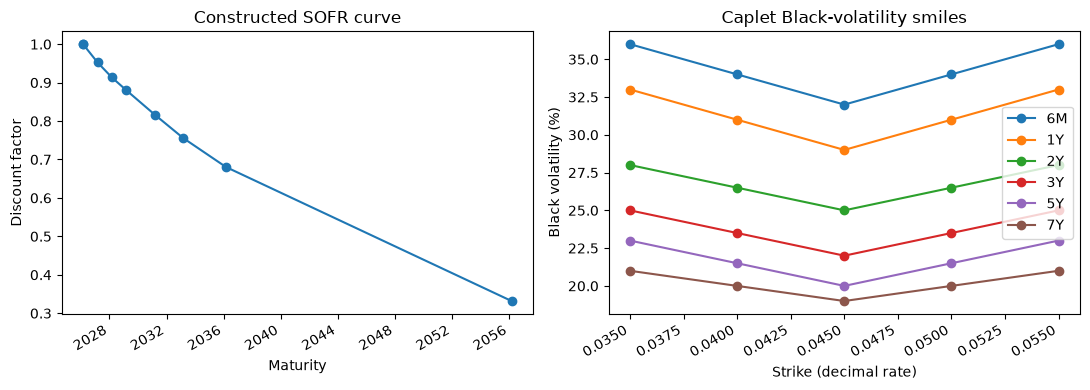

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(pd.to_datetime(nodes["date"]), nodes["discount_factor"], marker="o")
axes[0].set(title="Constructed SOFR curve", xlabel="Maturity", ylabel="Discount factor")
(smile * 100).plot(ax=axes[1], marker="o")
axes[1].set(
    title="Caplet Black-volatility smiles",
    xlabel="Strike (decimal rate)",
    ylabel="Black volatility (%)",
)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


## Revaluation under changed inputs

A quote scenario rebuilds the curve or surface from changed observations.
The rate shock below selects the deposit and OIS identifiers, while the
volatility shock uses one caplet-family selector.

Targets match sets of underscore-separated identifier segments. `SOFR` alone
would select both rate and volatility quotes here. Full caplet identifiers
can also overlap when tenor and expiry share a token, so listing every
volatility identifier could move some quotes more than once. We use the single
`CapletFloorlet_USD_SOFR` target and verify its transformed quotes below.
An absolute shock adds the supplied amount; a relative shock multiplies by
`1 + value`.


In [5]:
swap = qs.Swap(
    identifier="SWAP",
    start_date=ref,
    maturity_date=ref + "5Y",
    notional=1_000_000,
    fixed_rate=0.04,
    currency=qs.Currency.USD,
    market_index=qs.MarketIndex.SOFR,
)
caplet = qs.CapletFloorlet(
    identifier="CAPLET",
    fixing_date=ref + "2Y",
    start_accrual_date=ref + "2Y",
    end_accrual_date=ref + "2Y3M",
    payment_date=ref + "2Y3M",
    strike=0.045,
    currency=qs.Currency.USD,
    market_index=qs.MarketIndex.SOFR,
    payoff_type=qs.CapletFloorletType.Caplet,
)
swap_trade = qs.Trade(swap, ref)
caplet_trade = qs.Trade(caplet, ref, notional=1_000_000)
rate_up = [
    qs.Shock(target=label, value=0.001, shock_type=qs.ScenarioType.Absolute)
    for label in curve_spec["quotes"]
]
vol_up = [
    qs.Shock(
        target="CapletFloorlet_USD_SOFR",
        value=0.01,
        shock_type=qs.ScenarioType.Absolute,
    )
]


def observe_market(shocks):
    context = qs.PricingContext(
        quotes=market.quotes,
        curves=[curve_config],
        csa_policy=market.csa_policy,
        volatility_surfaces=[surface_config],
    )

    with context, qs.Scenario(shocks=shocks):
        return {
            "swap_pv_usd": context.evaluate(swap_trade).price,
            "caplet_pv_usd": context.evaluate(caplet_trade).price,
            "five_year_df": context.curve(qs.MarketIndex.SOFR).discount_factor(
                ref + "5Y"
            ),
            "two_year_vol": context.volatility_surface(qs.MarketIndex.SOFR).volatility(
                "2Y", 0.045
            ),
        }


comparison = pd.DataFrame(
    {
        "base": observe_market([]),
        "rates +10 bp": observe_market(rate_up),
        "vols +1 point": observe_market(vol_up),
    }
).T
comparison["swap_pnl_usd"] = (
    comparison["swap_pv_usd"] - comparison.loc["base", "swap_pv_usd"]
)
comparison["caplet_pnl_usd"] = (
    comparison["caplet_pv_usd"] - comparison.loc["base", "caplet_pv_usd"]
)
comparison


,swap_pv_usd,caplet_pv_usd,five_year_df,two_year_vol,swap_pnl_usd,caplet_pnl_usd
base,-1664.991324,571.899568,0.817367,0.25,0.000000,0.000000
rates +10 bp,-6081.828255,649.084288,0.813418,0.25,-4416.836932,77.184721
vols +1 point,-1664.991324,615.801139,0.817367,0.26,0.000000,43.901571


A higher rate market makes the agreed fixed coupon less attractive, reducing
the receive-fixed swap's PV. Its value stays unchanged under the separate
volatility move. The caplet gains from higher Black volatility; its rate
response combines changes in the forward and discount factor.


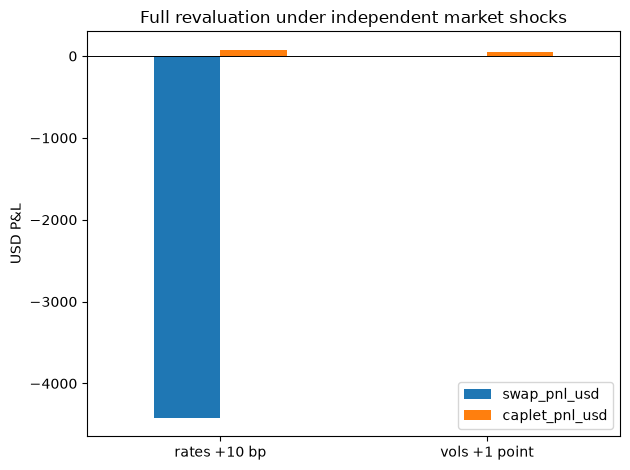

In [6]:
comparison[["swap_pnl_usd", "caplet_pnl_usd"]].iloc[1:].plot.bar(
    title="Full revaluation under independent market shocks", ylabel="USD P&L", rot=0
)
plt.axhline(0, color="black", linewidth=0.7)
plt.tight_layout()
plt.show()


## Interpolation and scenario checks

At a quoted expiry, this surface interpolates linearly between adjacent
strikes:

$$\sigma(K)=(1-w)\sigma(K_0)+w\sigma(K_1),\qquad
w=\frac{K-K_0}{K_1-K_0}.$$

We check an intermediate strike against the two quoted volatilities, then
verify that the volatility shock moves each intended quote once and leaves
rate quotes unchanged. The resulting curve and surface queries confirm
which market objects changed.


In [7]:
quotes = market.quotes.to_dataframe().set_index("identifier")["mid"]
low_label = "CapletFloorlet_USD_SOFR_3M_2Y_Absolute_0.035_Straddle_Black"
high_label = "CapletFloorlet_USD_SOFR_3M_2Y_Absolute_0.045_Straddle_Black"
interpolated_vol = (quotes.loc[low_label] + quotes.loc[high_label]) / 2
with context, qs.Scenario(shocks=vol_up):
    bumped_quotes = context.quotes.to_dataframe().set_index("identifier")["mid"]
quote_moves = bumped_quotes - quotes
print(f"Interpolated 2Y Black vol at 4% strike: {interpolated_vol:.2%}.")
print("Independent shocks leave the unrelated market object unchanged.")
comparison[["swap_pnl_usd", "caplet_pnl_usd", "five_year_df", "two_year_vol"]]


Interpolated 2Y Black vol at 4% strike: 26.50%.
Independent shocks leave the unrelated market object unchanged.


,swap_pnl_usd,caplet_pnl_usd,five_year_df,two_year_vol
base,0.000000,0.000000,0.817367,0.25
rates +10 bp,-4416.836932,77.184721,0.813418,0.25
vols +1 point,0.000000,43.901571,0.817367,0.26


The two scenario P&Ls show the swap's rate exposure and the caplet's joint
rate and volatility dependence. The interpolation check also identifies the
quantity being interpolated: Black volatility at a strike, with the configured
expiry conventions.


The [portfolio-risk study](../sensitivity/portfolio_risk.ipynb) compares local
quote derivatives with small full-revaluation bumps. For
[simulated rates](../hullwhite/simulations.ipynb) or
[callable bonds](../valuation/bonds/stepped_coupon_bond.ipynb), calibration
adds another step by converting Black option prices into absolute short-rate
model sigmas.
